# Fourier ligne par ligne et colonne par colonne

Sur la bande utile (y 500-1200) :
- **ligne par ligne** : pour chaque ligne $y$, FFT 1D le long de $x$. On obtient une image (fréquence horizontale $f_x$ en abscisse, $y$ en ordonnée). La berge (rochers, galets) est riche en hautes fréquences, l'eau beaucoup moins : la frontière apparaît comme une marche horizontale.
- **colonne par colonne** : pour chaque colonne $x$, FFT 1D le long de $y$ ($x$ en abscisse, fréquence verticale $f_y$ en ordonnée).

Pour chaque ligne (ou colonne), on calcule aussi l'**espérance** et la **variance** de la fréquence, en traitant le spectre de puissance normalisé $P(f) = |F(f)|^2 / \sum |F|^2$ comme une densité : $E[f] = \sum f\,P(f)$, $\mathrm{Var}[f] = \sum (f - E[f])^2 P(f)$.

Avant chaque FFT : moyenne retirée et fenêtre de Hann (contre les effets de bord). Les traits fins à $f$ = 0,125 ; 0,25 ; 0,375 viennent de la compression JPEG (blocs 8×8).

In [1]:
import sys
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from bucket import Bucket, DATA_DIR

plt.rcParams["figure.dpi"] = 70
b = Bucket()

CROP_Y0, CROP_Y1 = 500, 1200   # bande utile : sous le haut de l'enrochement, au-dessus de la plage du premier plan
W0 = 1919                      # largeur des images


def fetch(key):
    """Chemin local de l'image, téléchargée dans data/raw/ si elle n'y est pas déjà."""
    p = DATA_DIR / key
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        b.s3.download_file(b.name, key, str(p))
    return p


def load_band(key, scale=1, gray=False):
    """Bande CROP_Y0-CROP_Y1 en float (0-1), décodée directement à 1/scale (rapide)."""
    im = Image.open(fetch(key))
    if scale > 1:
        im.draft("L" if gray else "RGB", (im.size[0] // scale, im.size[1] // scale))
    s = W0 / im.size[0]
    im = im.convert("L" if gray else "RGB").crop((0, round(CROP_Y0 / s), im.size[0], round(CROP_Y1 / s)))
    return np.asarray(im, dtype=np.float32) / 255


In [2]:
# Quelques images typiques (clé dans le bucket)
EXEMPLES = {
    "nette 3 nov":      "romanche-01/2026/11/03/104512_02821fd2_s.jpg",
    "crue 30 mai":      "romanche-01/2026/05/30/113001_6f159d1d_s.jpg",
    "5 juillet":        "romanche-01/2026/07/05/110011_82f0a816_s.jpg",
    "brumeuse 16 sept": "romanche-01/2026/09/16/110012_8e17c446_s.jpg",
    "brouillard 12 oct": "romanche-01/2026/10/12/120006_16950012_s.jpg",
}
EXT = [0, W0, CROP_Y1, CROP_Y0]   # pour imshow : axes en pixels de l'image d'origine
AR = W0 / (CROP_Y1 - CROP_Y0)     # proportions de la bande (~2.7)

In [3]:
def spectra_1d(g):
    """FFT de chaque ligne de g (h, w). Renvoie f, log10|F|, E[f], Var[f] par ligne."""
    g = g - g.mean(axis=1, keepdims=True)
    F = np.fft.rfft(g * np.hanning(g.shape[1]), axis=1)
    f = np.fft.rfftfreq(g.shape[1])
    P = np.abs(F[:, 1:]) ** 2
    P = P / P.sum(axis=1, keepdims=True)
    E = (P * f[1:]).sum(axis=1)
    V = (P * (f[1:] - E[:, None]) ** 2).sum(axis=1)
    return f, np.log10(np.abs(F) + 1e-3), E, V


data = {}
for t, k in EXEMPLES.items():
    im = load_band(k)
    g = im.mean(axis=2)
    data[t] = (im, spectra_1d(g), spectra_1d(g.T))   # lignes, puis colonnes (transposée)
# même échelle de couleur pour toutes les images
allS = np.concatenate([d[1][1].ravel() for d in data.values()] + [d[2][1].ravel() for d in data.values()])
VMIN, VMAX = np.percentile(allS, [2, 99.8])

## Ligne par ligne
De gauche à droite : la bande, la FFT de chaque ligne (couleur = amplitude, log), puis $E[f]$ et $\mathrm{Var}[f]$ de chaque ligne, sur le même axe $y$.

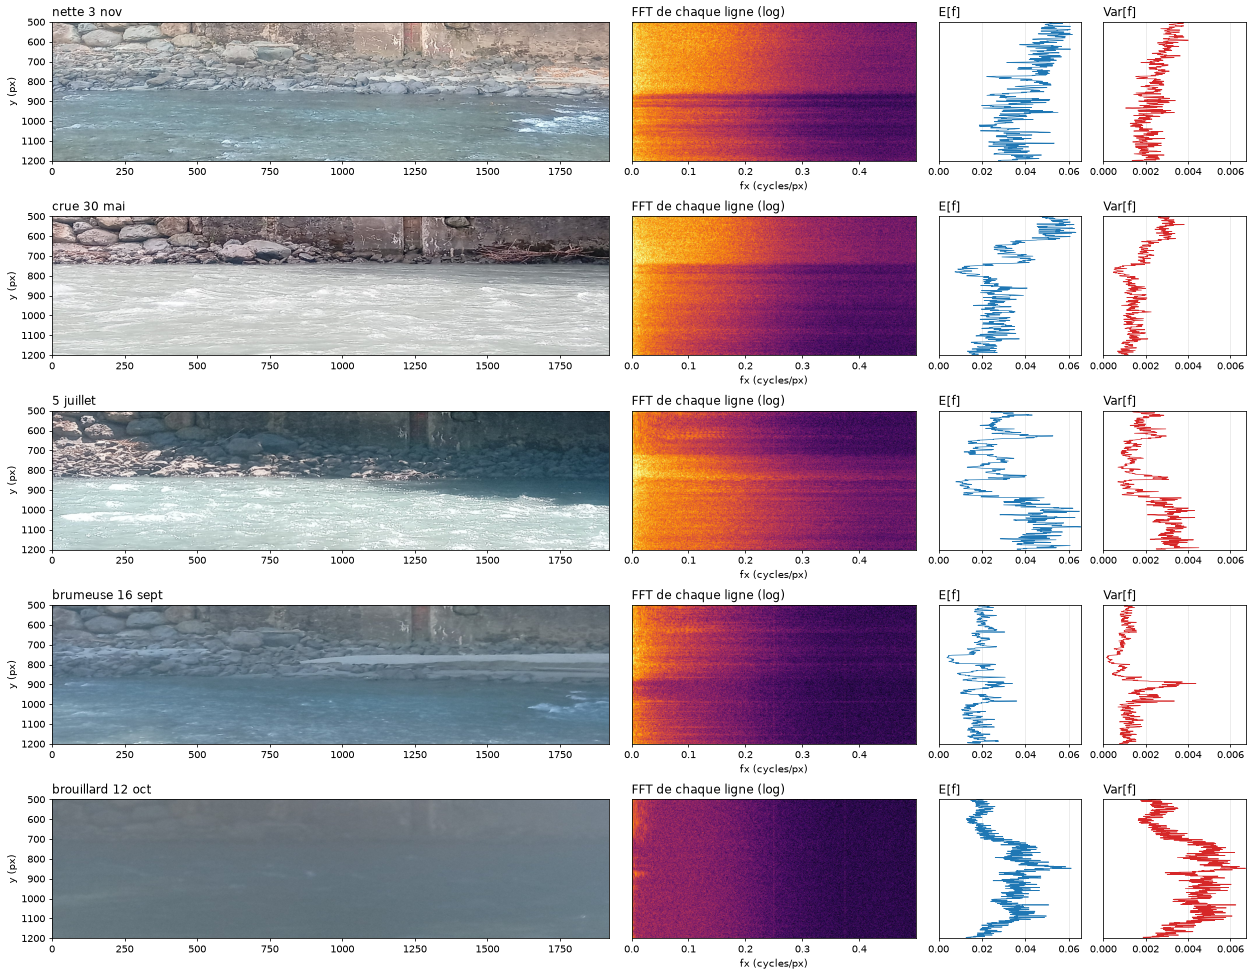

In [4]:
ys = np.arange(CROP_Y0, CROP_Y1)
Emax = max(d[1][2].max() for d in data.values()); Vmax = max(d[1][3].max() for d in data.values())
fig = plt.figure(figsize=(22, 3.4 * len(data)))
gs = fig.add_gridspec(len(data), 4, width_ratios=[AR, 1.4, 0.7, 0.7], hspace=0.4, wspace=0.08)
for i, (t, (im, (f, S, E, V), _)) in enumerate(data.items()):
    a = fig.add_subplot(gs[i, 0]); a.imshow(im, extent=EXT, aspect="auto"); a.set_title(t, loc="left")
    a.set_ylabel("y (px)")
    a = fig.add_subplot(gs[i, 1])
    a.imshow(S, extent=[f[0], f[-1], CROP_Y1, CROP_Y0], aspect="auto", cmap="inferno", vmin=VMIN, vmax=VMAX)
    a.set_yticks([]); a.set_xlabel("fx (cycles/px)"); a.set_title("FFT de chaque ligne (log)", loc="left")
    a = fig.add_subplot(gs[i, 2]); a.plot(E, ys, lw=.7); a.set_ylim(CROP_Y1, CROP_Y0); a.set_xlim(0, Emax)
    a.set_yticks([]); a.grid(alpha=.3); a.set_title("E[f]", loc="left")
    a = fig.add_subplot(gs[i, 3]); a.plot(V, ys, lw=.7, color="C3"); a.set_ylim(CROP_Y1, CROP_Y0); a.set_xlim(0, Vmax)
    a.set_yticks([]); a.grid(alpha=.3); a.set_title("Var[f]", loc="left")
plt.show()

## Colonne par colonne
De haut en bas : la bande, la FFT de chaque colonne ($x$ en abscisse, fréquence verticale $f_y$ en ordonnée), puis $E[f]$ et $\mathrm{Var}[f]$ de chaque colonne, sur le même axe $x$.

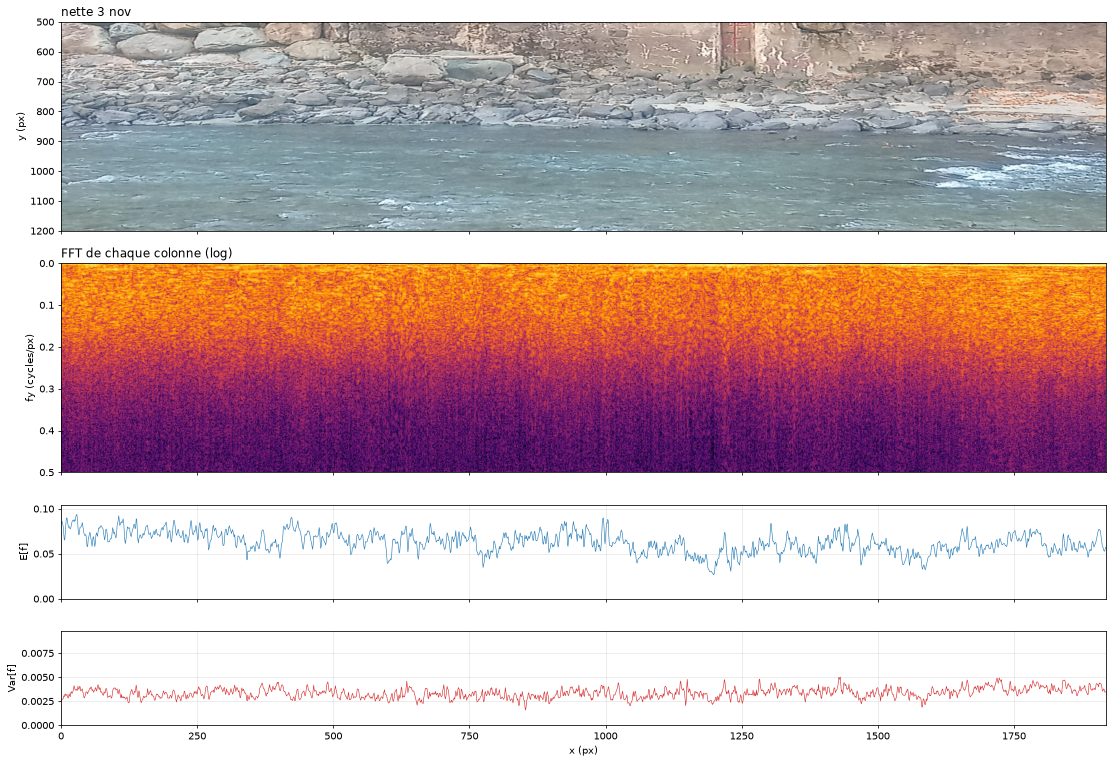

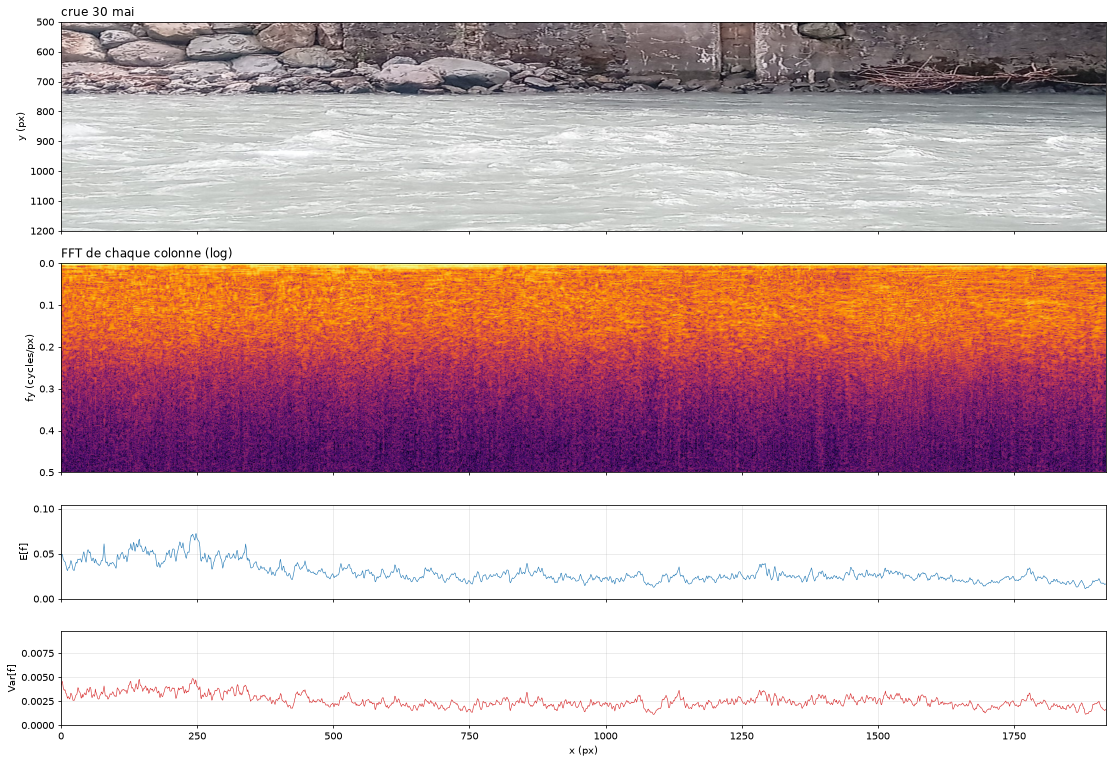

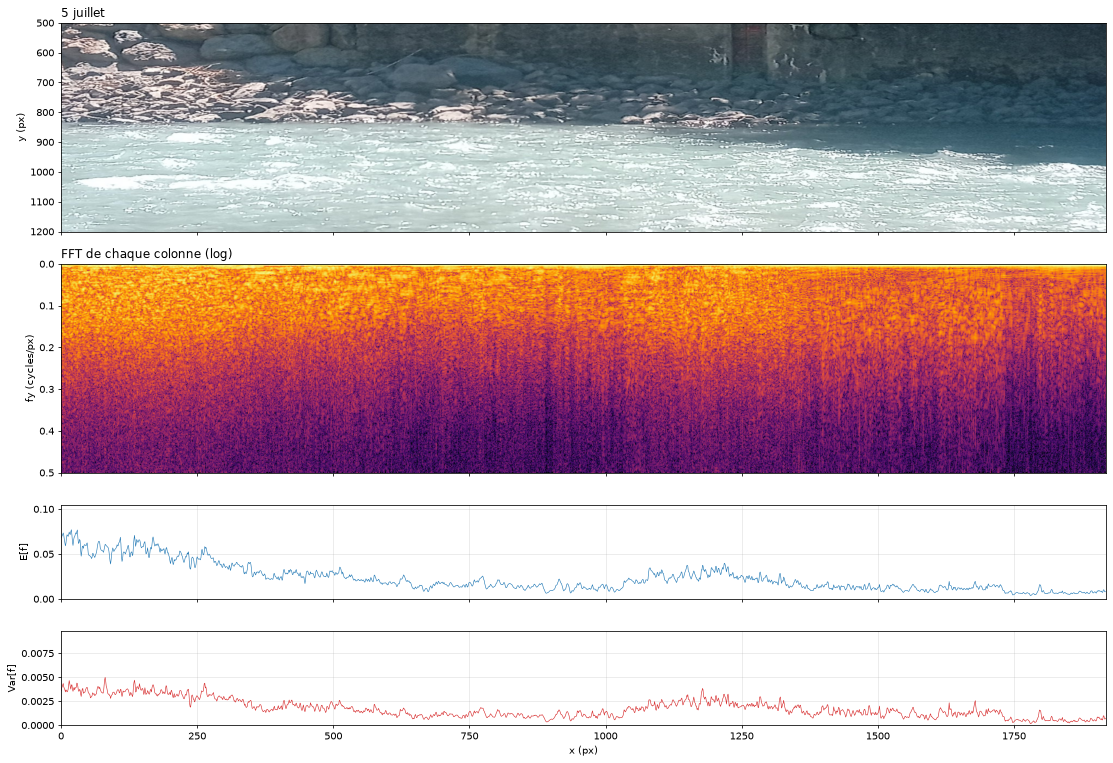

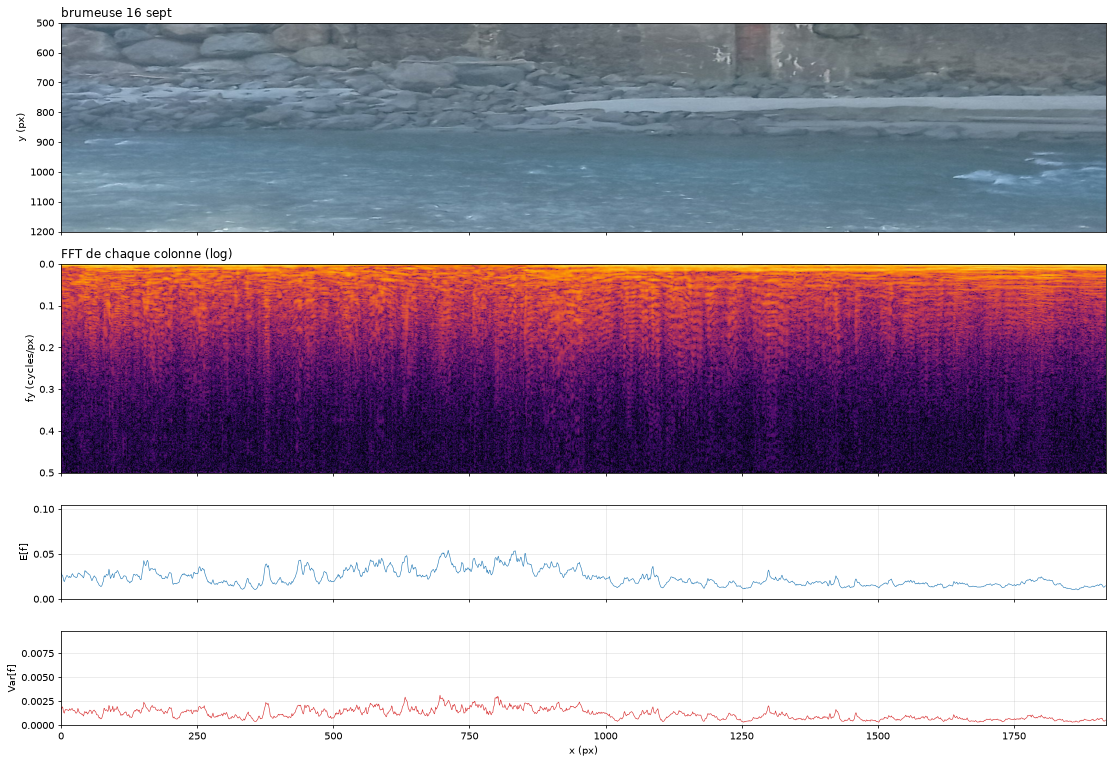

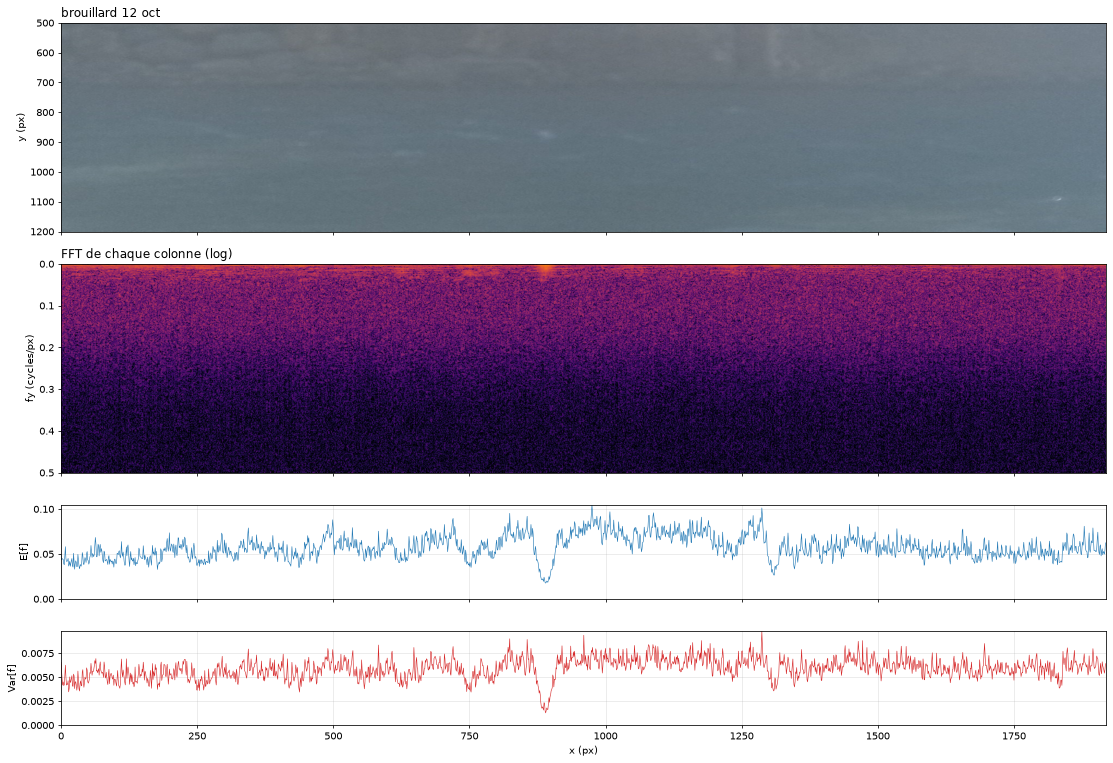

In [5]:
xs = np.arange(W0)
Emax = max(d[2][2].max() for d in data.values()); Vmax = max(d[2][3].max() for d in data.values())
for t, (im, _, (f, S, E, V)) in data.items():
    fig, ax = plt.subplots(4, 1, figsize=(16, 11), sharex=True, gridspec_kw={"height_ratios": [1, 1, 0.45, 0.45]})
    ax[0].imshow(im, extent=EXT, aspect="auto"); ax[0].set_title(t, loc="left"); ax[0].set_ylabel("y (px)")
    ax[1].imshow(S.T, extent=[0, W0, f[-1], f[0]], aspect="auto", cmap="inferno", vmin=VMIN, vmax=VMAX)
    ax[1].set_ylabel("fy (cycles/px)"); ax[1].set_title("FFT de chaque colonne (log)", loc="left")
    ax[2].plot(xs, E, lw=.6); ax[2].set_ylim(0, Emax); ax[2].set_ylabel("E[f]"); ax[2].grid(alpha=.3)
    ax[3].plot(xs, V, lw=.6, color="C3"); ax[3].set_ylim(0, Vmax); ax[3].set_ylabel("Var[f]"); ax[3].grid(alpha=.3)
    ax[3].set_xlabel("x (px)")
    plt.tight_layout(); plt.show()